# 05 Comparing conduit stats over different caves. 

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from os.path import exists, split, join
from os import makedirs
from tqdm import tqdm

import base.geometry as geom

from base.utils import list_all_descriptors, return_centreline_parametrisation

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


In [2]:
# change here the path to the repository of karst catalogue
data_repository = "F:/ScanLeica/data_paper/KarstConduitCatalogue" 
descriptor_filepaths = list_all_descriptors(data_repository)

In [3]:
descriptor_filepaths

['F:\\ScanLeica\\data_paper\\KarstConduitCatalogue\\Archamps\\PostEtroiture\\geometric_descriptors\\section_descriptors.txt',
 'F:\\ScanLeica\\data_paper\\KarstConduitCatalogue\\Archamps\\PreEtroiture\\geometric_descriptors\\section_descriptors.txt',
 'F:\\ScanLeica\\data_paper\\KarstConduitCatalogue\\BaumeDeLongeaigue\\GrandToboggan\\geometric_descriptors\\section_descriptors.txt',
 'F:\\ScanLeica\\data_paper\\KarstConduitCatalogue\\CascadeDeMotiers\\MainGallery\\geometric_descriptors\\section_descriptors.txt',
 'F:\\ScanLeica\\data_paper\\KarstConduitCatalogue\\CocaliereCotepatiere\\AvenDeLaCocaliere1\\geometric_descriptors\\section_descriptors.txt',
 'F:\\ScanLeica\\data_paper\\KarstConduitCatalogue\\CocaliereCotepatiere\\AvenDeLaCocaliere2\\geometric_descriptors\\section_descriptors.txt',
 'F:\\ScanLeica\\data_paper\\KarstConduitCatalogue\\CocaliereCotepatiere\\AvenDeLaCocaliere3\\geometric_descriptors\\section_descriptors.txt',
 'F:\\ScanLeica\\data_paper\\KarstConduitCatalogue\\C

Now we check the descriptor files which have been generated. 

In [4]:
valid_indices = [c for c, file in enumerate(descriptor_filepaths) if exists(file)]
print(valid_indices)

[4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 17]


In [5]:
with open(descriptor_filepaths[valid_indices[0]], "r") as f:
    header = f.readline()[2:-1].split(",")
    f.close()

In [6]:
all_data = []
for idx in valid_indices:
    data = np.loadtxt(descriptor_filepaths[idx], skiprows=1)

    the_index = np.ones(len(data))*idx
    indexed_data = np.vstack([the_index, data.T])

    all_data.append(indexed_data.T)

all_data = np.vstack(all_data)

In [7]:
def general_boxplot(ax, indexed_data, col, xpos, labels= None, color = "dodgerblue", xoffset = 0, xscale = 0.125):
   
    for thepos in xpos:
        thepos_tick = thepos+ xoffset
        isindex = np.argwhere(indexed_data[:, 0]==thepos).flatten()
        indexed_col_data = indexed_data[isindex, col]

        # scatter the median. 
        quantiles = np.quantile(indexed_col_data, [0.25, 0.5, 0.75, 0.005,0.995])
        iq = quantiles[2] -quantiles[0] 
        high_flyer = min(quantiles[1]+1.5*iq, quantiles[4]) 
        low_flyer = max(quantiles[1]-1.5*iq, quantiles[3])

        extreme_above = np.logical_and(indexed_col_data > high_flyer, indexed_col_data < quantiles[4])
        extreme_below = np.logical_and(indexed_col_data < low_flyer, indexed_col_data > quantiles[3])
        extremes = ((indexed_col_data[extreme_below], indexed_col_data[extreme_above]))


        ax.plot([thepos_tick-0.7*xscale, thepos_tick+0.7*xscale], [quantiles[1], quantiles[1]],lw = 2,  color = color)
        ax.plot([thepos_tick-xscale, thepos_tick+xscale], [quantiles[0], quantiles[0]], color = color)
        ax.plot([thepos_tick-xscale, thepos_tick+xscale], [quantiles[2], quantiles[2]], color = color)

        ax.plot([thepos_tick-0.4*xscale, thepos_tick+0.4*xscale], [low_flyer, low_flyer], color = color)
        ax.plot([thepos_tick-0.4*xscale, thepos_tick+0.4*xscale], [high_flyer, high_flyer], color = color)

        ax.plot([thepos_tick, thepos_tick], [low_flyer, quantiles[0]], color = color)
        ax.plot([thepos_tick, thepos_tick], [high_flyer, quantiles[2]], color = color)

        ax.plot([thepos_tick-xscale, thepos_tick-xscale], [quantiles[0], quantiles[2]], color = color)
        ax.plot([thepos_tick+xscale, thepos_tick+xscale], [quantiles[0], quantiles[2]], color = color)

        ax.scatter(len(extremes[0])* [thepos_tick], extremes[0], s = 1, color = color)
        ax.scatter(len(extremes[1])* [thepos_tick], extremes[1], s = 1, color = color)

        if labels != None:
            ax.set_xticks(xpos)
            ax.set_xticklabels(labels, rotation=90)

In [8]:
labels = [split(passage_filepath)[0].split("\\")[-2] for passage_filepath in descriptor_filepaths if exists(passage_filepath)]
print(labels)

['AvenDeLaCocaliere1', 'AvenDeLaCocaliere2', 'AvenDeLaCocaliere3', 'EventDeCotepatiere', 'PostVouteMouillante', 'PreVouteMouillante', 'DownstreamGallery', 'EntranceGallery', 'Filleul', 'EntranceGallery', 'KellerAquarium', 'EntranceGallery']


In [9]:

def summmary_boxplot_valid_conduits(thedescriptor, all_data, valid_indices, labels= None, output = None)-> None:
    fig, ax = plt.subplots(figsize=(4+len(valid_indices)/2, 4))

    units = geom.DESCRIPTOR_MAP[thedescriptor]["unit"]
    abbr = geom.DESCRIPTOR_MAP[thedescriptor]["abbr"]
    name = geom.DESCRIPTOR_MAP[thedescriptor]["name"]
    thecol = np.argwhere(np.array(header) == thedescriptor)[0]+1
    eq = geom.DESCRIPTOR_MAP[thedescriptor]["equation"]

    ax.set_title(name)

    general_boxplot(ax, all_data, thecol, xpos= valid_indices, labels = labels)
    ax.set_ylabel(f"{abbr} [{units}]")
    plt.tight_layout()
    if output != None:
        plt.savefig(output)

    plt.show();


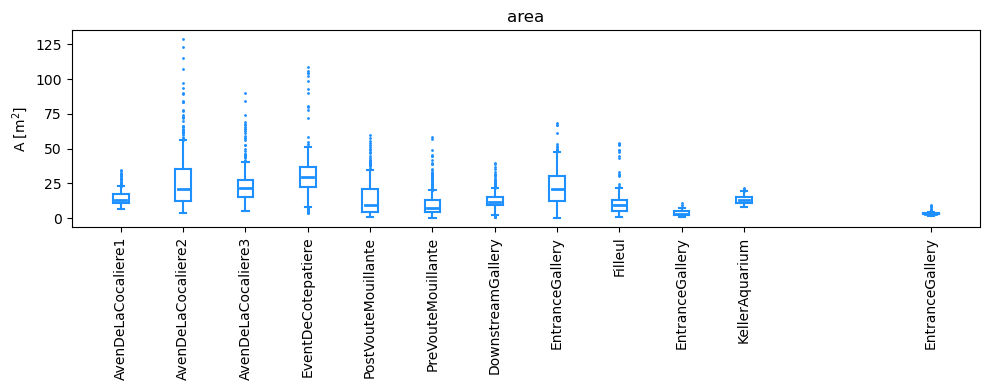

In [10]:
summmary_boxplot_valid_conduits("area", all_data, valid_indices, labels, output = "./temp/summary_boxplot_area.png")

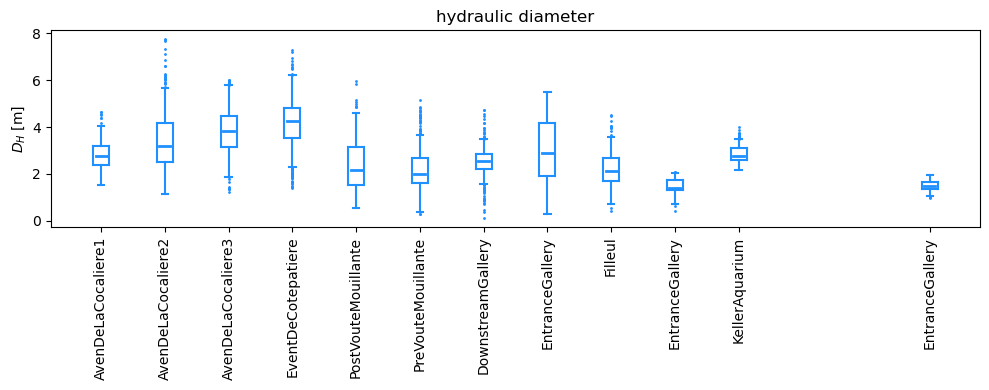

In [11]:
summmary_boxplot_valid_conduits("hydraulic_diameter", all_data, valid_indices, labels, output = "./temp/summary_boxplot_hydraulic_diameter.png")

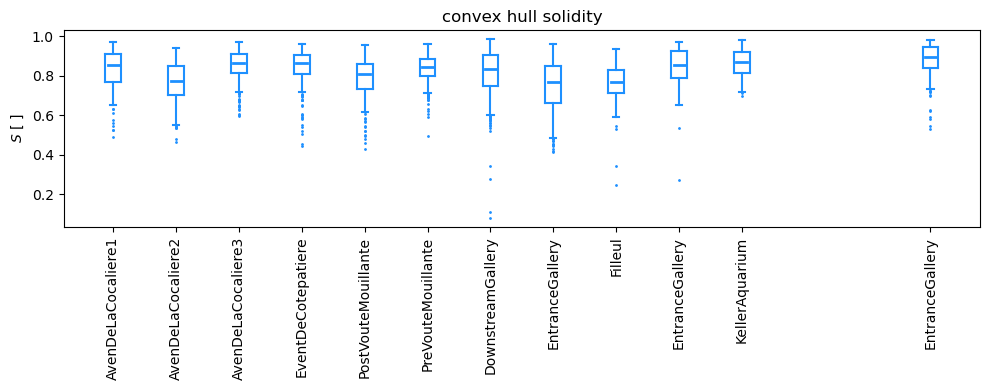

In [12]:
summmary_boxplot_valid_conduits("solidity", all_data, valid_indices, labels, output = "./temp/summary_boxplot_solidity.png")

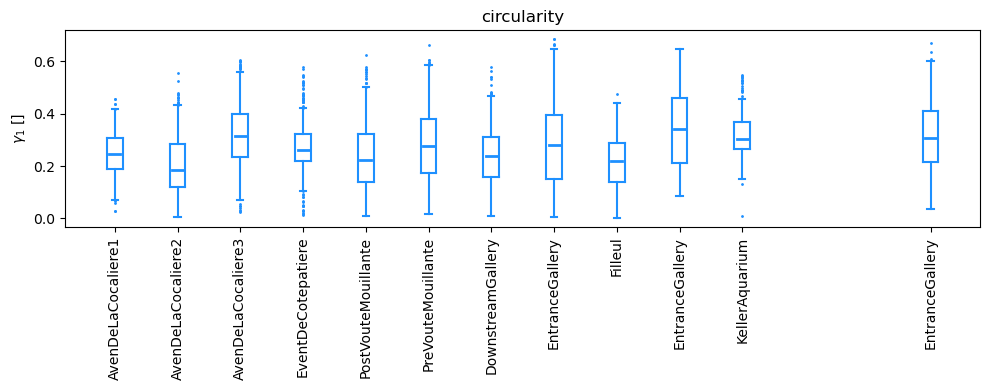

In [13]:
summmary_boxplot_valid_conduits("circularity", all_data, valid_indices, labels, output = "./temp/summary_boxplot_circularity.png")